In [2]:
!pip install network

  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Created wheel for network: filename=network-0.1-py3-none-any.whl size=3144 sha256=00a8f6a3f30d484336dffd28ba647587641e51645cc27490146f5893a3bf5281
  Stored in directory: c:\users\admin\appdata\local\pip\cache\wheels\3a\9a\a4\341d3b109494a43a5cdd444ca83be3a4bfe8c1267ad9f85332
Successfully built network



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import networkx as nx
import matplotlib.pyplot as plt

In [7]:
G = nx.karate_club_graph()

In [10]:
num_nodes = len(G.nodes)
true_labels = torch.tensor(
    [0 if G.nodes[i]['club'] == 'Mr. Hi' else 1 for i in range(num_nodes)],
    dtype=torch.long
)

In [11]:
A = torch.zeros((num_nodes, num_nodes), dtype=torch.float32)
for u,v in G.edges:
    A[u,v] = 1.0
    A[v,u] = 1.0

X = torch.eye(num_nodes, dtype=torch.float32)

In [12]:
def compute_renormalized_adjacency(adj: torch.Tensor) -> torch.Tensor:
    adj_tilde = adj + torch.eye(adj.size(0))
    deg_tilde = torch.sum(adj_tilde, dim = 1)
    deg_inv_sqrt = torch.pow(deg_tilde, -0.5)
    deg_inv_sqrt[torch.isinf(deg_inv_sqrt)] = 0.0
    d_mat_inv_sqrt = torch.diag(deg_inv_sqrt)
    return d_mat_inv_sqrt @ adj_tilde @d_mat_inv_sqrt

In [14]:
A_hat = compute_renormalized_adjacency(A)

In [15]:
train_mask = torch.zeros(num_nodes, dtype=torch.bool)
train_mask[0] = True
train_mask[33] = True

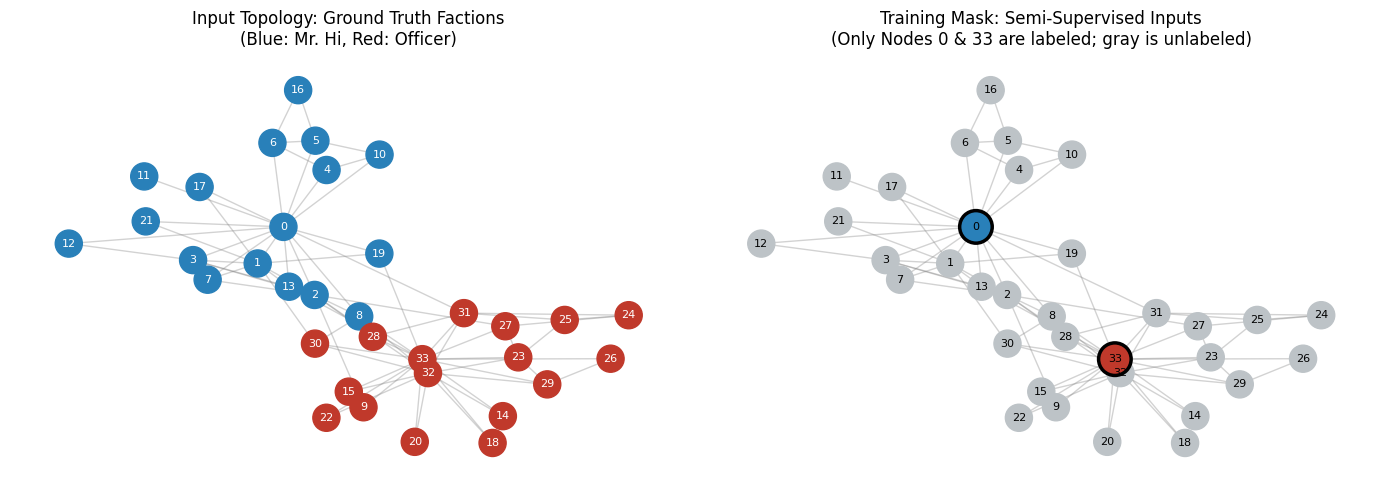

In [16]:
pos = nx.spring_layout(G, seed=42)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
gt_colors = ['#2980b9' if y == 0 else '#c0392b' for y in true_labels.numpy()]
nx.draw_networkx_nodes(G, pos, ax=axes[0], node_color=gt_colors, node_size=380)
nx.draw_networkx_edges(G, pos, ax=axes[0], alpha=0.35, edge_color='gray')
nx.draw_networkx_labels(G, pos, ax=axes[0], font_size=8, font_color='white')
axes[0].set_title("Input Topology: Ground Truth Factions\n(Blue: Mr. Hi, Red: Officer)")
axes[0].axis('off')

# Plot 2: Semi-Supervised Mask (What the GCN actually receives)
mask_colors = ['#bdc3c7'] * num_nodes
mask_colors[0] = '#2980b9'
mask_colors[33] = '#c0392b'

nx.draw_networkx_nodes(G, pos, ax=axes[1], node_color=mask_colors, node_size=380)
nx.draw_networkx_edges(G, pos, ax=axes[1], alpha=0.35, edge_color='gray')
nx.draw_networkx_labels(G, pos, ax=axes[1], font_size=8, font_color='black')
# Emphasize labeled training nodes with a black border
nx.draw_networkx_nodes(G, pos, nodelist=[0, 33], ax=axes[1], 
                       node_color=['#2980b9', '#c0392b'], node_size=550, 
                       edgecolors='black', linewidths=2.5)
axes[1].set_title("Training Mask: Semi-Supervised Inputs\n(Only Nodes 0 & 33 are labeled; gray is unlabeled)")
axes[1].axis('off')

plt.tight_layout()
plt.show()

In [17]:
class GCNLayer(nn.Module):
    def __init__(self, in_features: int, out_features: int):
        super().__init__()
        self.weight = nn.Parameter(torch.FloatTensor(in_features, out_features))
        nn.init.xavier_uniform_(self.weight)

    def forward(self, h: torch.Tensor, adj_norm: torch.Tensor) -> torch.Tensor:
        support = torch.matmul(h, self.weight)
        return torch.matmul(adj_norm, support)

In [18]:
class KarateGCN(nn.Module):
    def __init__(self, in_dim: int, hidden_dim: int, num_classes: int):
        super().__init__()
        self.conv1 = GCNLayer(in_dim, hidden_dim)
        self.conv2 = GCNLayer(hidden_dim, num_classes)

    def forward(self, x: torch.Tensor, adj_norm: torch.Tensor):
        h_hidden = F.relu(self.conv1(x, adj_norm))
        logits = self.conv2(h_hidden, adj_norm)
        return logits, h_hidden
    

In [19]:
model = KarateGCN(in_dim=num_nodes, hidden_dim=2, num_classes=2)
optimizer = torch.optim.Adam(model.parameters(), lr = 0.015, weight_decay=5e-4)
criterion = nn.CrossEntropyLoss()

In [20]:
print("Training GCN on Karate Club...")
for epoch in range(1,151):
    model.train()
    optimizer.zero_grad()
    logits, _ = model(X, A_hat)
    loss = criterion(logits[train_mask], true_labels[train_mask])
    loss.backward()
    optimizer.step()
    if epoch % 30 == 0 or epoch == 1:
        model.eval()
        with torch.no_grad():
            preds = torch.argmax(logits, dim = 1)
            acc = (preds==true_labels).sum().item() / num_nodes
            print(f'Epoch {epoch:3d} | Train Loss: {loss.item():.4f} | Graph-wide Accuracy: {acc * 100:.1f}%')

model.eval()
with torch.no_grad():
    final_logits, latent_2d = model(X, A_hat)
    final_probs = F.softmax(final_logits, dim = 1)
    final_preds = torch.argmax(final_logits, dim = 1)

print("\n--- Model Output Summary ---")
print(f"Total Nodes Classified: {num_nodes}")
print(f"Correct Predictions:    {(final_preds == true_labels).sum().item()} / {num_nodes}")
print(f"Overall Accuracy:       {((final_preds == true_labels).sum().item() / num_nodes) * 100:.2f}%")

Training GCN on Karate Club...
Epoch   1 | Train Loss: 0.7060 | Graph-wide Accuracy: 47.1%
Epoch  30 | Train Loss: 0.5803 | Graph-wide Accuracy: 88.2%
Epoch  60 | Train Loss: 0.1470 | Graph-wide Accuracy: 94.1%
Epoch  90 | Train Loss: 0.0260 | Graph-wide Accuracy: 97.1%
Epoch 120 | Train Loss: 0.0122 | Graph-wide Accuracy: 97.1%
Epoch 150 | Train Loss: 0.0084 | Graph-wide Accuracy: 97.1%

--- Model Output Summary ---
Total Nodes Classified: 34
Correct Predictions:    33 / 34
Overall Accuracy:       97.06%


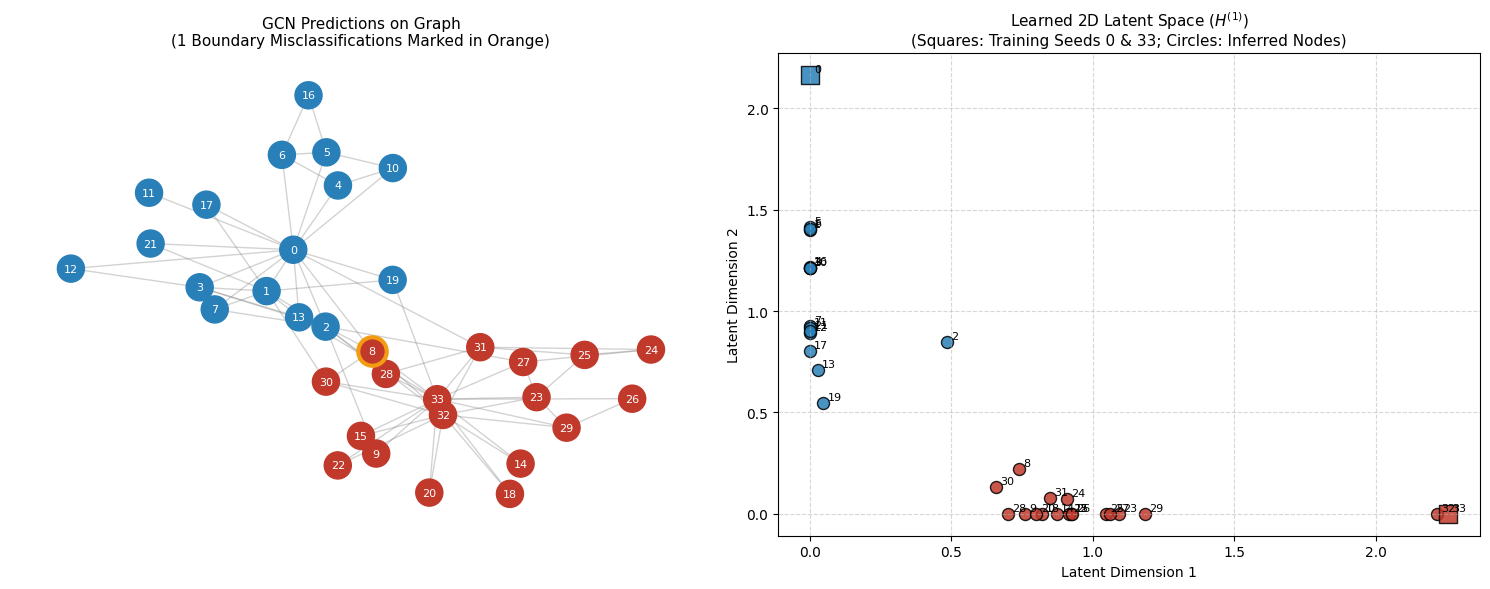


--- Prediction Probabilities for Key Nodes ---
Node  0 (TRAIN SEED) | P(Mr. Hi) = 0.991 | P(Officer) = 0.009 | Pred = 0 (True: 0)
Node 33 (TRAIN SEED) | P(Mr. Hi) = 0.008 | P(Officer) = 0.992 | Pred = 1 (True: 1)
Node  8 (INFERRED  ) | P(Mr. Hi) = 0.223 | P(Officer) = 0.777 | Pred = 1 (True: 0)
Node  9 (INFERRED  ) | P(Mr. Hi) = 0.175 | P(Officer) = 0.825 | Pred = 1 (True: 1)
Node 30 (INFERRED  ) | P(Mr. Hi) = 0.166 | P(Officer) = 0.834 | Pred = 1 (True: 1)


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: Topological Classification Result
pred_colors = ['#2980b9' if p == 0 else '#c0392b' for p in final_preds.numpy()]
nx.draw_networkx_nodes(G, pos, ax=axes[0], node_color=pred_colors, node_size=380)
nx.draw_networkx_edges(G, pos, ax=axes[0], alpha=0.35, edge_color='gray')
nx.draw_networkx_labels(G, pos, ax=axes[0], font_size=8, font_color='white')

# Highlight misclassified nodes with an orange border
misclassified = [i for i in range(num_nodes) if final_preds[i] != true_labels[i]]
if misclassified:
    nx.draw_networkx_nodes(G, pos, nodelist=misclassified, ax=axes[0], 
                           node_color=[pred_colors[i] for i in misclassified], 
                           node_size=420, edgecolors='#f39c12', linewidths=3.0)
    axes[0].set_title(f"GCN Predictions on Graph\n({len(misclassified)} Boundary Misclassifications Marked in Orange)", fontsize=11)
else:
    axes[0].set_title("GCN Predictions on Graph (100% Accuracy)", fontsize=11)
axes[0].axis('off')

# Subplot 2: 2D Latent Bottleneck Space (H^(1))
latent_np = latent_2d.numpy()
for i in range(num_nodes):
    c = '#2980b9' if final_preds[i] == 0 else '#c0392b'
    marker = 's' if train_mask[i] else 'o'
    size = 180 if train_mask[i] else 75
    
    axes[1].scatter(latent_np[i, 0], latent_np[i, 1], color=c, marker=marker, s=size, edgecolors='black', alpha=0.85)
    axes[1].text(latent_np[i, 0] + 0.015, latent_np[i, 1] + 0.015, str(i), fontsize=8)

axes[1].set_title("Learned 2D Latent Space ($H^{(1)}$)\n(Squares: Training Seeds 0 & 33; Circles: Inferred Nodes)", fontsize=11)
axes[1].set_xlabel("Latent Dimension 1")
axes[1].set_ylabel("Latent Dimension 2")
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# 2. Inspecting Probabilistic Confidence of Boundary Nodes
# -------------------------------------------------------------
print("\n--- Prediction Probabilities for Key Nodes ---")
key_nodes = [0, 33, 8, 9, 30]  # Leaders (0, 33) and classical boundary nodes (8, 9, 30)
for node_id in key_nodes:
    p0 = final_probs[node_id, 0].item()
    p1 = final_probs[node_id, 1].item()
    status = "TRAIN SEED" if train_mask[node_id] else "INFERRED"
    print(f"Node {node_id:2d} ({status:10s}) | P(Mr. Hi) = {p0:.3f} | P(Officer) = {p1:.3f} | Pred = {final_preds[node_id].item()} (True: {true_labels[node_id].item()})")